In [5]:
import ctypes, glob, sys
for lib in glob.glob(f"{sys.prefix}/lib/python3*/site-packages/nvidia/cusolver/lib/libcusolver.so.*"):
    ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL)

import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
import pickle
import numpy as np

C10_DIR = "docs/cifar-10-batches-py"
C100_DIR = "docs/cifar-100-python"

def unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")

def to_images(flat):
    return np.asarray(flat).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

# CIFAR-10
c10_names = [n.decode() for n in unpickle(f"{C10_DIR}/batches.meta")[b"label_names"]]
batches = [unpickle(f"{C10_DIR}/data_batch_{i}") for i in range(1, 6)]
x10_train = to_images(np.concatenate([b[b"data"] for b in batches]))
y10_train = np.concatenate([b[b"labels"] for b in batches])
test10 = unpickle(f"{C10_DIR}/test_batch")
x10_test = to_images(test10[b"data"])
y10_test = np.asarray(test10[b"labels"])

# CIFAR-100
meta100 = unpickle(f"{C100_DIR}/meta")
fine_names = [n.decode() for n in meta100[b"fine_label_names"]]
coarse_names = [n.decode() for n in meta100[b"coarse_label_names"]]
train100 = unpickle(f"{C100_DIR}/train")
test100 = unpickle(f"{C100_DIR}/test")
x100_train = to_images(train100[b"data"])
y100_fine_train = np.array(train100[b"fine_labels"])
y100_coarse_train = np.array(train100[b"coarse_labels"])
x100_test = to_images(test100[b"data"])
y100_fine_test = np.array(test100[b"fine_labels"])
y100_coarse_test = np.array(test100[b"coarse_labels"])

print(x10_train.shape)
print(x10_test.shape)
print(x100_train.shape)
print(x100_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 32, 32, 3)
(10000, 32, 32, 3)


# Visual test of CIFAR 10 / 100 images

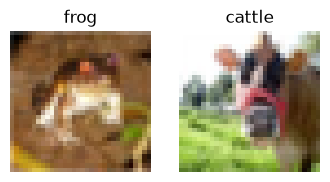

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(4, 2))
axes[0].imshow(x10_train[0]); axes[0].set_title(c10_names[y10_train[0]])
axes[1].imshow(x100_train[0]); axes[1].set_title(fine_names[y100_fine_train[0]])
for ax in axes:
    ax.axis("off")
plt.show()

# Phase 2: Filter and combine the 24 classes

Keep 7 classes from CIFAR-10, 16 fine classes and the `trees` superclass from CIFAR-100, then relabel them to a single 0-23 range.

In [8]:
num_classes = 24
c10_classes = ["automobile", "bird", "cat", "deer", "dog", "horse", "truck"]
c100_classes = [
    "cattle", "fox", "baby", "boy", "girl", "man", "woman", "rabbit", "squirrel",
    "bicycle", "bus", "motorcycle", "pickup_truck", "train", "lawn_mower", "tractor",
]
class_names = c10_classes + c100_classes + ["trees"]


def extract_classes(X, y, source_names, wanted_classes):
    X_selected = []
    y_selected = []
    for name in wanted_classes:
        X_class = X[y == source_names.index(name)]
        X_selected.append(X_class)
        y_selected.append(np.full(len(X_class), class_names.index(name)))
    return np.concatenate(X_selected), np.concatenate(y_selected)


def combine_datasets(X10, y10, X100, y100_fine, y100_coarse):
    X_a, y_a = extract_classes(X10, y10, c10_names, c10_classes)
    X_b, y_b = extract_classes(X100, y100_fine, fine_names, c100_classes)
    X_c, y_c = extract_classes(X100, y100_coarse, coarse_names, ["trees"])
    return np.concatenate((X_a, X_b, X_c)), np.concatenate((y_a, y_b, y_c))


def check_data(X_train, y_train, X_test, y_test):
    print(X_train.shape)
    print(X_test.shape)
    assert(len(class_names) == num_classes), "The number of class names is not 24"
    assert(X_train.shape[0] == y_train.shape[0]), "The number of training images does not match the number of labels"
    assert(X_test.shape[0] == y_test.shape[0]), "The number of test images does not match the number of labels"
    assert(X_train.shape[1:] == (32, 32, 3)), "The dimensions of the training images are not 32 x 32 x 3"
    assert(X_test.shape[1:] == (32, 32, 3)), "The dimensions of the test images are not 32 x 32 x 3"
    assert(X_train.shape[0] == 45500), "The training set should have 45500 images"
    assert(X_test.shape[0] == 9100), "The test set should have 9100 images"


X_train, y_train = combine_datasets(x10_train, y10_train, x100_train, y100_fine_train, y100_coarse_train)
X_test, y_test = combine_datasets(x10_test, y10_test, x100_test, y100_fine_test, y100_coarse_test)
check_data(X_train, y_train, X_test, y_test)

for class_id, name in enumerate(class_names):
    print(class_id, name)

(45500, 32, 32, 3)
(9100, 32, 32, 3)
0 automobile
1 bird
2 cat
3 deer
4 dog
5 horse
6 truck
7 cattle
8 fox
9 baby
10 boy
11 girl
12 man
13 woman
14 rabbit
15 squirrel
16 bicycle
17 bus
18 motorcycle
19 pickup_truck
20 train
21 lawn_mower
22 tractor
23 trees


# Phase 3: Explore the data

How many images are there, what size are they, and which classes do they represent?

In [9]:
def summarise_data(X_train, X_test):
    print("CIFAR-10 keys:", test10.keys())
    print("CIFAR-100 keys:", test100.keys())
    print("Training images:", X_train.shape[0])
    print("Test images:", X_test.shape[0])
    print("Image size:", X_train.shape[1:])
    print("Number of classes:", num_classes)


summarise_data(X_train, X_test)

CIFAR-10 keys: dict_keys([b'batch_label', b'labels', b'data', b'filenames'])
CIFAR-100 keys: dict_keys([b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data'])
Training images: 45500
Test images: 9100
Image size: (32, 32, 3)
Number of classes: 24


## Sample images from each class

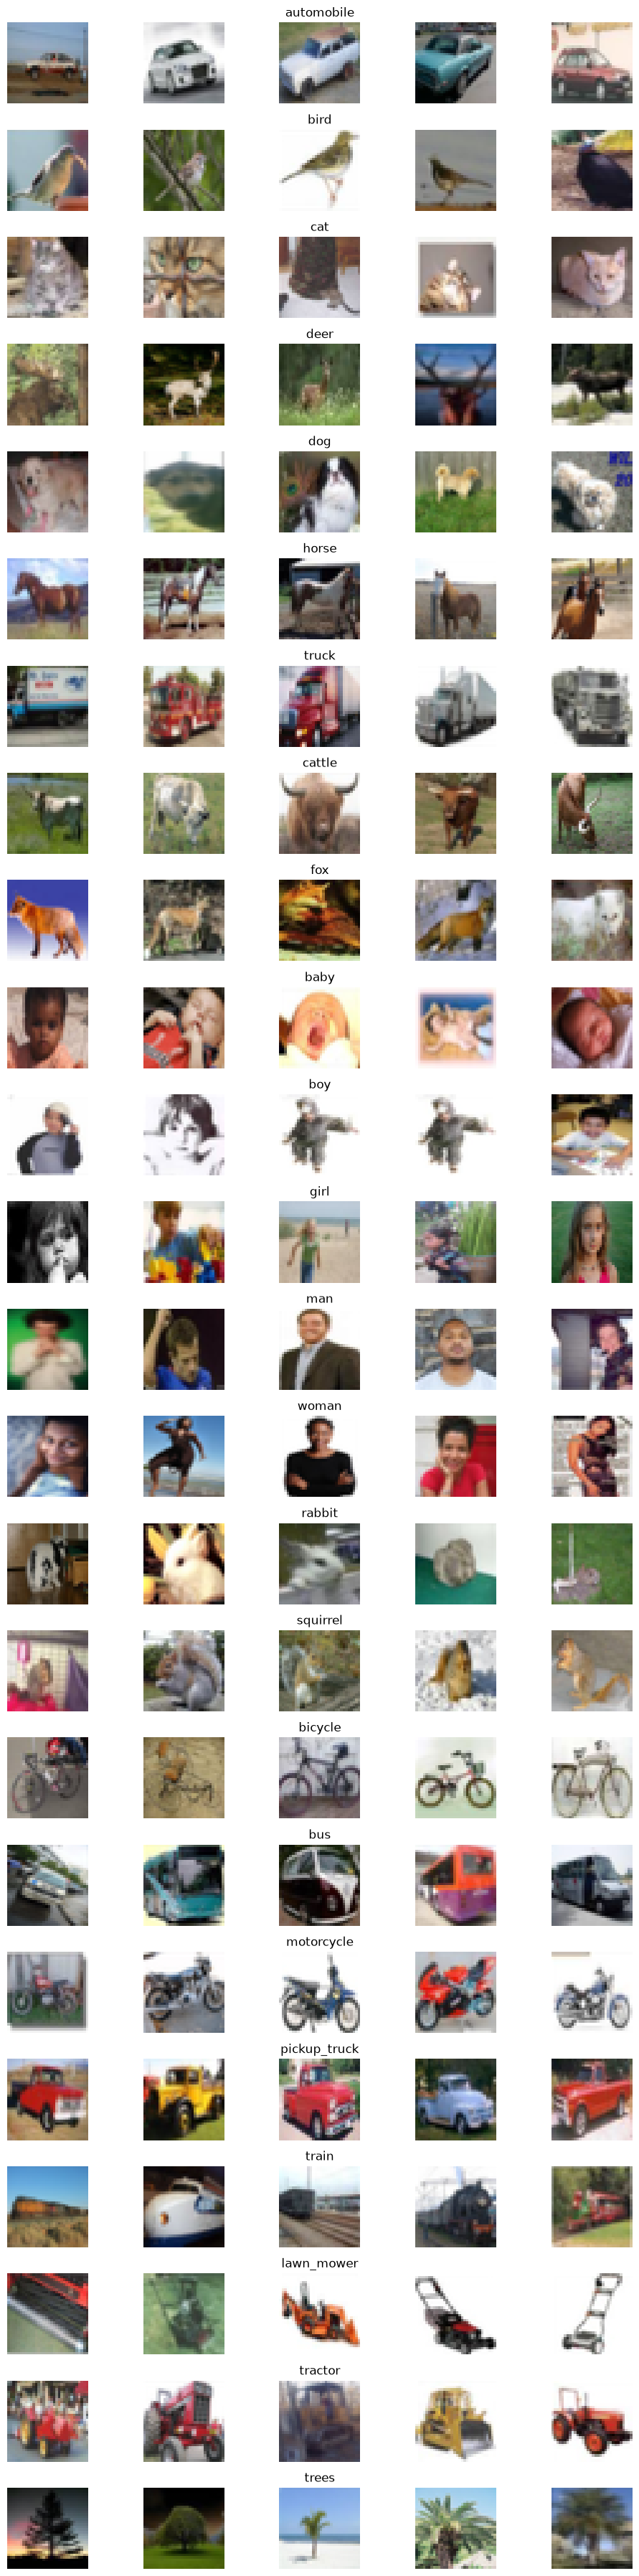

In [10]:
np.random.seed(0)


def show_training_samples(num_classes, class_names, X_train, y_train):
    num_samples = []
    cols = 5
    fig, axs = plt.subplots(nrows=num_classes, ncols=cols, figsize=(10, 36))
    for i in range(cols):
        for j in range(num_classes):
            x_selected = X_train[y_train == j]
            axs[j][i].imshow(x_selected[np.random.randint(0, len(x_selected) - 1), :, :])
            axs[j][i].axis("off")
            if i == 2:
                axs[j][i].set_title(class_names[j])
                num_samples.append(len(x_selected))
    fig.tight_layout()
    plt.show()
    return num_samples


num_of_each_class = show_training_samples(num_classes, class_names, X_train, y_train)

## Number of images per class

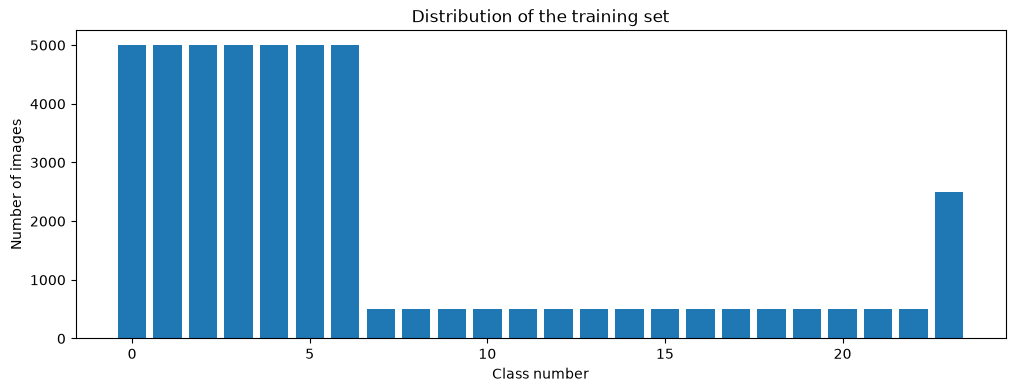

0 automobile 5000
1 bird 5000
2 cat 5000
3 deer 5000
4 dog 5000
5 horse 5000
6 truck 5000
7 cattle 500
8 fox 500
9 baby 500
10 boy 500
11 girl 500
12 man 500
13 woman 500
14 rabbit 500
15 squirrel 500
16 bicycle 500
17 bus 500
18 motorcycle 500
19 pickup_truck 500
20 train 500
21 lawn_mower 500
22 tractor 500
23 trees 2500


In [11]:
def plot_sample_distribution(num_classes, num_of_each_class):
    plt.figure(figsize=(12, 4))
    plt.bar(range(0, num_classes), num_of_each_class)
    plt.title("Distribution of the training set")
    plt.xlabel("Class number")
    plt.ylabel("Number of images")
    plt.show()


plot_sample_distribution(num_classes, num_of_each_class)

for class_id, name in enumerate(class_names):
    print(class_id, name, num_of_each_class[class_id])